# Faster tours: before and after

One prompt, run through the agent twice: once on the version before the speed changes (**baseline**),
once after (**faster**). Each run is saved whole in `eval/runs/<version>.json`: the reply, every live
step with its time, and every tool call.

**The prompt:** *"I have an hour and love animals, especially cats and horses. Plan me a tour."*

**What changed in "faster":**
1. Storytellers and the Writer think at **low** instead of high (the Guide stays at high).
2. A Storyteller still working at **75 s** is stopped; that stop uses the Researcher's cited facts.
3. The Guide no longer **retypes the route and evidence** into `write_tour`; the code passes them along.
4. Each stop is **sent to the page as soon as its story is ready**, so the tour fills in one by one.

To re-run: `uv run python eval/run_prompt.py <label>`, then re-run this notebook.
One run each, so expect some noise: the Researchers can pick different objects each time.

In [1]:
import json, sys, html
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Markdown
sys.path.insert(0, ".")
import compare

A, B = "baseline", "faster"
runs = {v: compare.load(v) for v in (A, B)}

## 1. Speed

In [2]:
pd.DataFrame([compare.summary(runs[v]) for v in (A, B)]).set_index("version").T

version,baseline,faster
total (s),157.2,95.9
first stop on screen (s),157.2,45.6
last story done (s),131.8,78.9
agents,15.0,14.0
tool calls,97.0,80.0
stops,9.0,8.0
avg story words,196.0,169.0
Wikipedia articles cited,24.0,16.0
stops with Look for,9.0,8.0
stopped at time limit,0.0,0.0


**First stop on screen** is when the visitor can start reading: in the baseline, nothing shows until
the whole tour is done; in the faster version, it is when the first stop's story arrives.

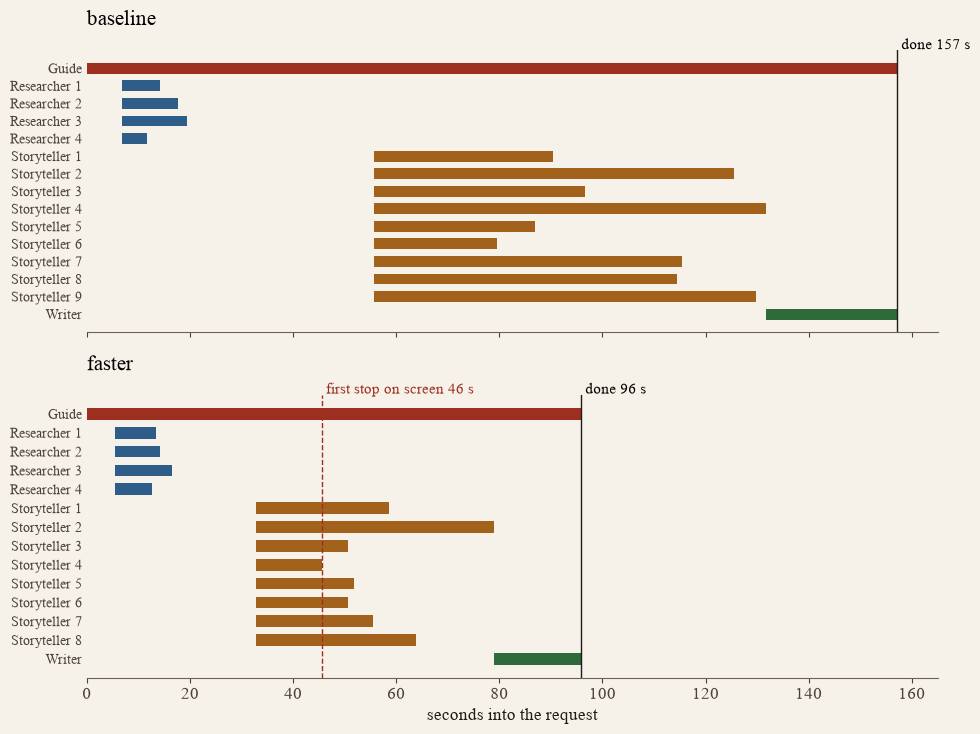

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12, "axes.edgecolor": "#6b6257",
                     "axes.labelcolor": "#1f1b16", "xtick.color": "#4a4239", "ytick.color": "#4a4239"})
COLORS = {"Guide": "#9c2f1f", "Researcher": "#2f5d8a", "Storyteller": "#a3621c", "Writer": "#2f6b3a"}

fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, facecolor="#f6f2ea")
for ax, v in zip(axes, (A, B)):
    ax.set_facecolor("#f6f2ea")
    spans = compare.stages(runs[v])
    total = runs[v]["timing"]["total_s"]
    for i, s in enumerate(spans):
        kind = s["agent"].split(" ")[0]
        end = s["end"] if s["end"] is not None else total
        ax.barh(i, end - s["start"], left=s["start"], height=0.62, color=COLORS.get(kind, "#6b6257"))
    ax.set_yticks(range(len(spans)), [s["agent"] for s in spans], fontsize=10)
    ax.invert_yaxis()
    shown = runs[v]["timing"].get("first_stop_shown_s")
    ax.axvline(total, color="#1f1b16", lw=1)
    ax.text(total, -0.9, f" done {total:.0f} s", fontsize=11, va="bottom")
    if shown:
        ax.axvline(shown, color="#9c2f1f", lw=1, ls="--")
        ax.text(shown, -0.9, f" first stop on screen {shown:.0f} s", fontsize=11, va="bottom", color="#9c2f1f")
    ax.set_title(v, loc="left", fontsize=15, pad=18)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[-1].set_xlabel("seconds into the request")
plt.tight_layout()
plt.show()

## 2. The stops, side by side

In [4]:
def stop_table(v):
    return pd.DataFrame(compare.stops(runs[v]["reply"]))[["n", "title", "gallery", "words", "met_cites", "wikipedia_cites", "look_for", "fallback"]]

for v in (A, B):
    display(Markdown(f"**{v}**"))
    display(stop_table(v).set_index("n"))

**baseline**

,title,gallery,words,met_cites,wikipedia_cites,look_for,fallback
n,,,,,,,
1,Cat Statuette intended to contain a mummified cat,134,209,3,2,True,False
2,Horse Armor Probably Made for Count Antonio I...,371,219,4,2,True,False
3,唐 三彩陶馬|Horse,207,193,3,3,True,False
4,Two Children Teasing a Cat,637,193,2,3,True,False
5,The Silver Tureen,629,185,4,2,True,False
6,The Horse Fair,812,184,2,3,True,False
7,Three Jockeys,817,177,3,3,True,False
8,唐 彩繪泥塑騎馬仕女俑|Horse and female rider,207,207,6,2,True,False
9,明 玉雕馬上封侯|Horse and monkey,222,194,3,4,True,False


**faster**

,title,gallery,words,met_cites,wikipedia_cites,look_for,fallback
n,,,,,,,
1,Horse Armor Probably Made for Count Antonio I...,371,172,4,1,True,False
2,Parade Saddle,373,136,5,2,True,False
3,The Horse Fair,812,200,2,4,True,False
4,Two Children Teasing a Cat,637,180,2,2,True,False
5,The Silver Tureen,629,167,4,1,True,False
6,Cat Statuette intended to contain a mummified cat,134,185,3,2,True,False
7,Figure of a Seated Cat,130,167,3,2,True,False
8,Lion Cub,101,144,3,2,True,False


`words` is the story's length; `met_cites` and `wikipedia_cites` count its source tags;
`fallback` means the stop has no story of its own (the Storyteller failed or hit the time limit).

## 3. The two tours in full

In [5]:
import re
def as_html(text):
    # Light Markdown → HTML, enough to read the tours: headings, emphasis, paragraphs, lists
    out = []
    for block in re.split(r"\n{2,}", html.escape(text)):
        b = block.strip()
        if not b:
            continue
        b = re.sub(r"\*(.+?)\*", r"<i>\1</i>", b)
        b = re.sub(r"\[(met|wikipedia|data)[^\]]*\]", r"<span style='color:#8a7f70;font-size:11px'>[\1]</span>", b)
        m = re.match(r"^(#{2,3}) (.+)", b)
        if m:
            tag = "h3" if m.group(1) == "##" else "h4"
            rest = b[m.end():].strip()
            out.append(f"<{tag} style='margin:18px 0 4px'>{m.group(2)}</{tag}>" + (f"<p>{rest.replace(chr(10), '<br>')}</p>" if rest else ""))
        else:
            out.append(f"<p>{b.replace(chr(10), '<br>')}</p>")
    return "".join(out)

col = "flex:1;min-width:0;padding:0 18px;font-family:'Times New Roman',serif;font-size:14px;line-height:1.5"
display(HTML(f"""<div style='display:flex;gap:8px;align-items:flex-start'>
<div style='{col};border-right:1px solid #d6cab6'><h2 style='color:#9c2f1f'>{A}</h2>{as_html(runs[A]['reply'])}</div>
<div style='{col}'><h2 style='color:#9c2f1f'>{B}</h2>{as_html(runs[B]['reply'])}</div></div>"""))

## 4. Your scores

Read both tours above and fill in 1 (poor) to 5 (excellent). The criteria are the same ones the LLM judge uses.

| Criterion | What to look for | baseline | faster |
|---|---|---|---|
| Relevance | Do the stops fit cats, horses and one hour? | | |
| Explanation | Would a non-expert understand each object and why it matters? | | |
| Grounding | Does every fact have a source? Anything that looks made up? | | |
| Look for | Concrete and useful in front of the object? | | |
| Writing | Warm, clear, good read aloud? | | |
| Completeness | Every stop has a real story; the route works? | | |
| **Overall** | Which would you rather walk with? | | |

## 5. LLM judge

The judge (Gemini 3.5 Flash, high thinking) sees both tours **blind**, as Tour A and Tour B, with the
rubric in `compare.RUBRIC`. It judges twice with the order swapped, because judges tend to favor one
position; each verdict is then unblinded. The exact text it sees is saved as `eval/judge_pack.md`, so
you can paste it into any other model to get a second opinion.

In [6]:
text, key = compare.judge_pack(A, B, seed=0)
Path("judge_pack.md").write_text(text); Path("judge_key.json").write_text(json.dumps(key, indent=1))
verdicts = compare.judge(A, B)
rows = []
for v in verdicts:
    for version, scores in v["scores"].items():
        rows.append({"judge order": v["order"], "version": version, **(scores or {})})
display(pd.DataFrame(rows).set_index(["judge order", "version"]))
for v in verdicts:
    display(Markdown(f"**Order {v['order']}** → better: **{v['better']}** ({v['difference']}). {v['reasons']}  \n"
                     f"Weakest stops: {v['weakest_stops']}"))
Path("runs/judge.json").write_text(json.dumps(verdicts, indent=1, ensure_ascii=False))

relevance  explanation  grounding  look_for  \
judge order          version                                                 
A=baseline, B=faster baseline          5            5          5         4   
                     faster            4            5          5         5   
A=faster, B=baseline faster            5            5          5         5   
                     baseline          5            5          5         3   

                               writing  completeness  
judge order          version                          
A=baseline, B=faster baseline        5             5  
                     faster          5             5  
A=faster, B=baseline faster          5             5  
                     baseline        4             4

**Order A=baseline, B=faster** → better: **baseline** (clear). Tour A is better overall because of its globally diverse selection of objects, introducing beautiful Chinese Tang and Ming dynasty works alongside European and Egyptian art to create a richer historical narrative. Additionally, Tour A's 'Before you go' disclaimers are highly sophisticated, addressing genuine scholarly ambiguities and data gaps (such as the attribution of the horse armor or the artist's self-portrait) rather than the generic platitudes found in Tour B. While Tour B has slightly more detailed 'Look for' prompts, Tour A's inclusion of actual animal representations (like the Tang ceramic horse) is more satisfying than Tour B's inclusion of a saddle or a lion cub.  
Weakest stops: {'baseline': [], 'faster': ['2', '8']}

**Order A=faster, B=baseline** → better: **faster** (clear). Tour A is clearly better because its 'Look for' prompts are highly concrete and direct the visitor's eyes to specific, easily missed details (such as a hospital dome in the background of the painting or the mounting pins on the cat statue), whereas Tour B's prompts are disappointingly generic. Additionally, Tour A organizes its physical route much more logically, keeping the adjacent Arms and Armor galleries together on the first floor before moving upstairs, whereas Tour B jumps erratically between wings. Finally, Tour A's narrative voice is warmer and more engaging to read aloud.  
Weakest stops: {'faster': ['8'], 'baseline': ['6']}

2261

## 6. Verdict

Keep "faster" unless the judge (in both orders) or your own scores show a clear or large drop in
explanation, grounding or completeness. To roll back the thinking level without touching code, set
`STORY_EFFORT=high` on Cloud Run; to remove the time limit, set `STORY_TIMEOUT=0`.